# code_065 · Physical constraints and conditions

**Book:** section 13.4. A self-contained structure-preserving input laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_13_GUIDE.md), [run evidence](../CHAPTER_13_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_065).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1365;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1365


<a id="forward"></a>
## Specify the physical task before choosing a learner

A static homogeneous Euler–Bernoulli cantilever has length L=3 m, constant flexural rigidity EI=8 MN m² and uniform downward load q=5 kN/m. Positive w is downward displacement. Under the stated slender/small-deflection linear model, EI*d4w/dx4=q in the interior; clamping imposes w(0)=dw/dx(0)=0 and the free tip imposes d2w/dx2(L)=d3w/dx3(L)=0. Integrating gives w=q*x²*(6L²-4Lx+x²)/(24EI), tip q*L⁴/(8EI). Primary reference: MIT 1.050 Solid Mechanics Fall 2004 [problem-set formula sheet, page 2](https://ocw.mit.edu/courses/1-050-solid-mechanics-fall-2004/fd4eff39aec922b8c07660006f40686e_pset04_11.pdf). This is an analytic construction check, not field validation, a PINN fit or an operator-network benchmark.

Static equilibrium has no initial state. A separately recorded dynamic extension would need density/area, time-dependent forcing, initial displacement and velocity in addition to compatible boundary conditions. Its schema below states initial rest, but no transient solution is computed. Measured q/EI are distinct from imposed support/constitutive assumptions.


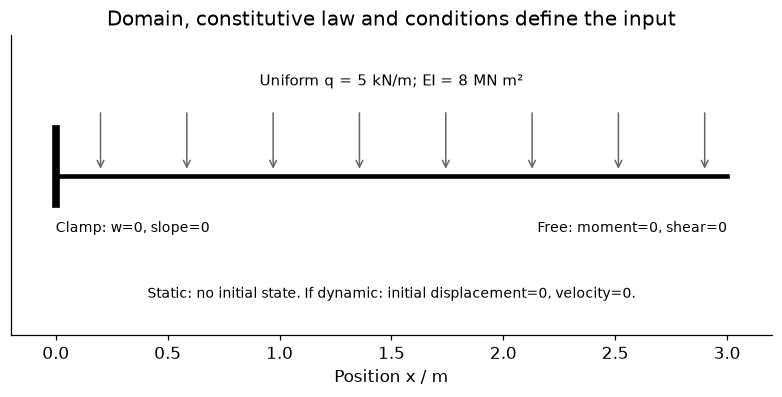

In [2]:
L=3.;q=5000.;EI=8e6;x=np.linspace(0,L,101)
def fields(x,q,EI,L):
 x=np.asarray(x);w=q*(6*L*L*x*x-4*L*x**3+x**4)/(24*EI);d1=q*(12*L*L*x-12*L*x*x+4*x**3)/(24*EI);d2=q*(12*L*L-24*L*x+12*x*x)/(24*EI);d3=q*(-24*L+24*x)/(24*EI);d4=np.full_like(x,q/EI,dtype=float);return w,d1,d2,d3,d4
w,d1,d2,d3,d4=fields(x,q,EI,L)
np.testing.assert_allclose([w[0],d1[0],d2[-1],d3[-1]],0,atol=1e-14);np.testing.assert_allclose(EI*d4,q);np.testing.assert_allclose(w[-1],q*L**4/(8*EI))
assert q>0 and EI>0 and L>0
static_contract={'task':'static cantilever forward displacement','geometry':{'length_m':L},'material':{'EI_N_m2':EI,'law':'homogeneous linear Euler-Bernoulli'},'forcing':{'uniform_q_N_per_m':q},'boundary':{'x0':['w=0','slope=0'],'xL':['curvature=0','third_derivative=0']},'initial_state':'not applicable to static task','output':'w in m, positive downward'}
dynamic_extension={'not_solved':True,'additional_inputs':['mass_per_length_kg_per_m','q(x,t)','time_domain'],'initial_displacement':'w(x,0)=0 m','initial_velocity':'dw/dt(x,0)=0 m/s'}
RESULTS['static_contract']=static_contract;RESULTS['dynamic_schema_only']=dynamic_extension;RESULTS['tip_displacement_mm']=float(1000*w[-1]);RESULTS['boundary_and_balance_checks_passed']=True
fig,ax=plt.subplots(figsize=(7,3.5));ax.plot([0,L],[0,0],color='black',lw=3);ax.plot([0,0],[-.15,.25],color='black',lw=5)
for xx in np.linspace(.2,L-.1,8):ax.annotate('',xy=(xx,.02),xytext=(xx,.35),arrowprops=dict(arrowstyle='->',color='.4'))
ax.text(L/2,.48,'Uniform q = 5 kN/m; EI = 8 MN m²',ha='center',fontsize=10);ax.text(0,-.3,'Clamp: w=0, slope=0',fontsize=9);ax.text(L,-.3,'Free: moment=0, shear=0',ha='right',fontsize=9);ax.text(L/2,-.65,'Static: no initial state. If dynamic: initial displacement=0, velocity=0.',ha='center',fontsize=9);ax.set(xlim=(-.2,L+.2),ylim=(-.85,.75),xlabel='Position x / m',yticks=[],title='Domain, constitutive law and conditions define the input');plt.show()


<a id="inverse"></a>
## A complete forward task need not identify an inverse task

The full static field depends on q/EI. Doubling both produces exactly the same displacement: even noiseless full-field observations cannot separate two unknowns in this model without other information. If q and geometry are known independently, a positive tip observation can estimate EI through q*L⁴/(8*w_tip). Generate twenty noisy repeated tip readings with .02 mm standard deviation and retain the resulting spread as this measurement experiment's sensitivity. It is not a posterior interval or a field uncertainty guarantee. Unknown supports, load calibration or constitutive discrepancy create additional ambiguity not modeled by those repeats.


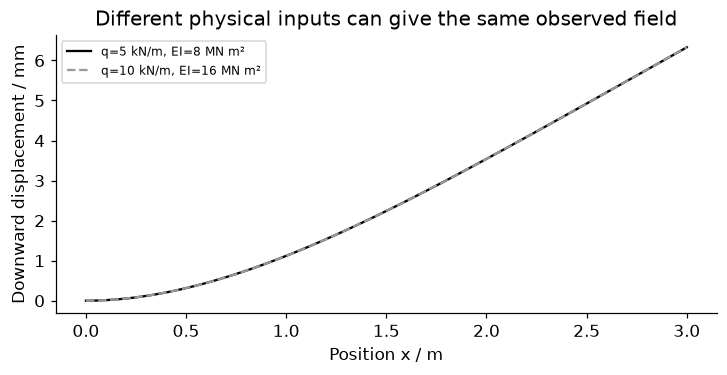

In [3]:
np.testing.assert_allclose(fields(x,2*q,2*EI,L)[0],w);observations=w[-1]+rng.normal(0,.02e-3,20);assert np.all(observations>0);estimates=q*L**4/(8*observations)
RESULTS['inverse_known_load_EI_MN_m2']={'mean':float(estimates.mean()/1e6),'sd_across_readings':float(estimates.std(ddof=1)/1e6),'min':float(estimates.min()/1e6),'max':float(estimates.max()/1e6),'observations':20};RESULTS['unknown_load_stiffness_ratio_ambiguity_passed']=True
fig,ax=plt.subplots(figsize=(6.5,3.3));ax.plot(x,1000*w,color='black',label='q=5 kN/m, EI=8 MN m²');ax.plot(x,1000*fields(x,2*q,2*EI,L)[0],color='.6',ls='--',label='q=10 kN/m, EI=16 MN m²');ax.set(xlabel='Position x / m',ylabel='Downward displacement / mm',title='Different physical inputs can give the same observed field');ax.legend(fontsize=8);plt.show()


In [4]:
summary={'example_id':'code_065','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['constitutive assumptions and conservation balance', 'supports boundary loads and initial-state schema', 'forward input completeness', 'inverse load-stiffness non-identifiability'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["constitutive assumptions and conservation balance", "supports boundary loads and initial-state schema", "forward input completeness", "inverse load-stiffness non-identifiability"], "elapsed_seconds": 0.131, "example_id": "code_065", "hardware": "Darwin arm64 CPU", "results": {"boundary_and_balance_checks_passed": true, "dynamic_schema_only": {"additional_inputs": ["mass_per_length_kg_per_m", "q(x,t)", "time_domain"], "initial_displacement": "w(x,0)=0 m", "initial_velocity": "dw/dt(x,0)=0 m/s", "not_solved": true}, "inverse_known_load_EI_MN_m2": {"max": 8.032825960928387, "mean": 7.997917124679079, "min": 7.947596971229724, "observations": 20, "sd_across_readings": 0.02252697177459991}, "static_contract": {"boundary": {"x0": ["w=0", "slope=0"], "xL": ["curvature=0", "third_derivative=0"]}, "forcing": {"uniform_q_N_per_m": 5000.0}, "geometry": {"length_m": 3.0}, "initial_state": "not applicable to static task", "material": {"EI_N_m2": 80